In [2]:
import seaborn as sns
df = sns.load_dataset("taxis")

In [3]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [8]:
missing_counts = df.isnull().sum()
print("Columns with missing values:")
print(missing_counts[missing_counts > 0])

Columns with missing values:
Series([], dtype: int64)


In [7]:
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=['object', 'category']).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

C:\Users\HP\AppData\Local\Temp\ipykernel_19928\3161575096.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object', 'category']).columns:


In [10]:
critical_columns = ['distance', 'fare', 'pickup', 'dropoff']

existing_critical = [col for col in critical_columns if col in df.columns]
df = df.dropna(subset=existing_critical)

print("Total missing values left:", df.isnull().sum().sum())

Total missing values left: 0


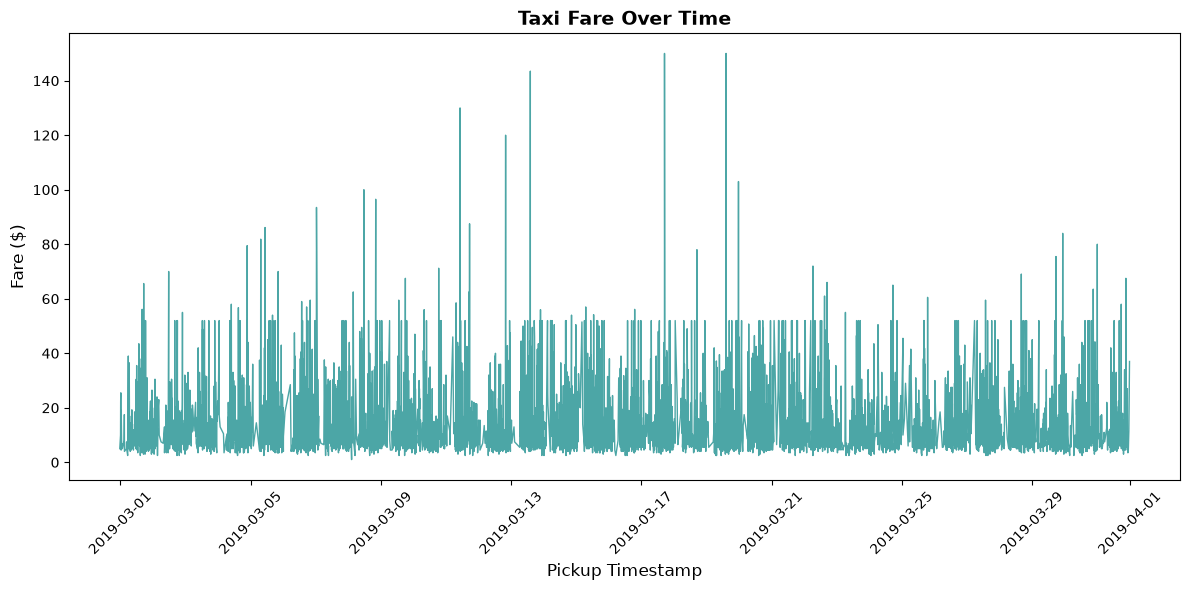

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df['pickup'] = pd.to_datetime(df['pickup'])

df_sorted = df.sort_values('pickup')

plt.figure(figsize=(12, 6))
plt.plot(df_sorted['pickup'], df_sorted['fare'], color='teal', alpha=0.7, linewidth=1)

plt.title('Taxi Fare Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Pickup Timestamp', fontsize=12)
plt.ylabel('Fare ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

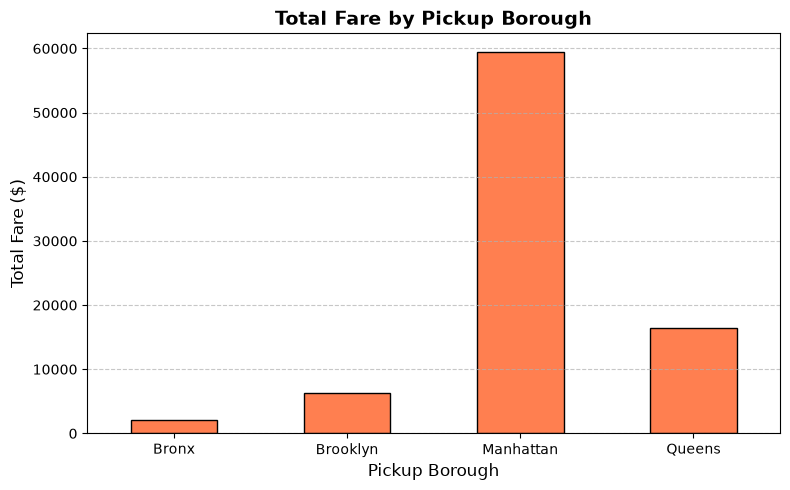

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

borough_fares = df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(8, 5))
borough_fares.plot(kind='bar', color='coral', edgecolor='black')

plt.title('Total Fare by Pickup Borough', fontsize=14, fontweight='bold')
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Total Fare ($)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

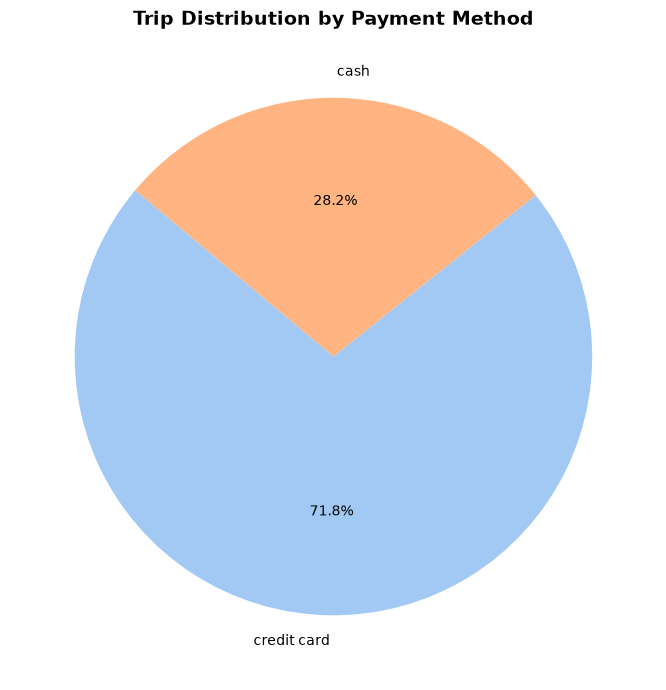

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

payment_counts = df['payment'].value_counts()

plt.figure(figsize=(7, 7))
payment_counts.plot(
    kind='pie', 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=sns.color_palette('pastel')
)

plt.title('Trip Distribution by Payment Method', fontsize=14, fontweight='bold')
plt.ylabel('') 
plt.tight_layout()
plt.show()

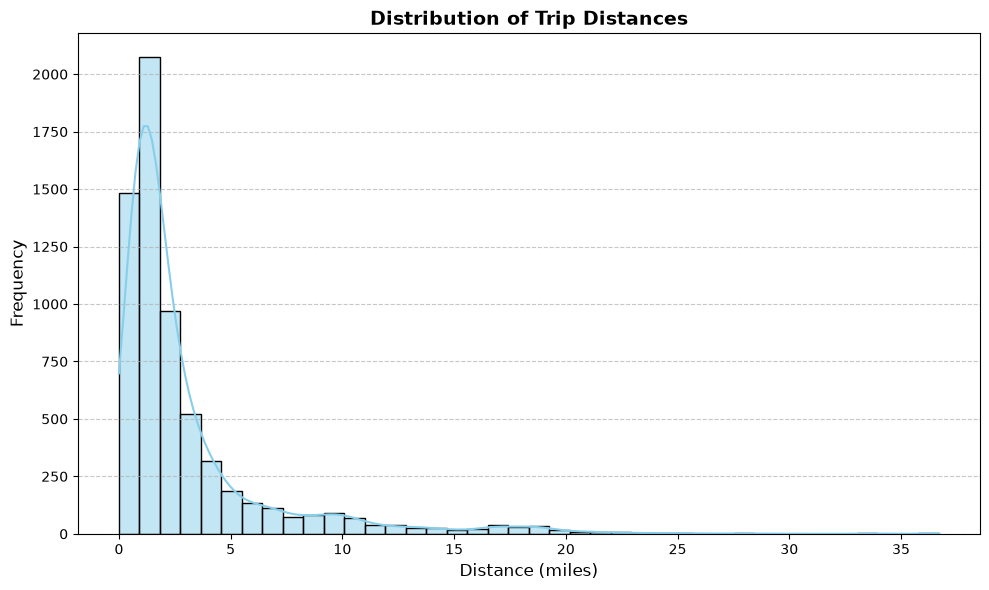

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['distance'], bins=40, kde=True, color='skyblue', edgecolor='black')

plt.title('Distribution of Trip Distances', fontsize=14, fontweight='bold')
plt.xlabel('Distance (miles)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_19928\3063598541.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='pickup_borough', y='tip', data=df, palette='Set2')


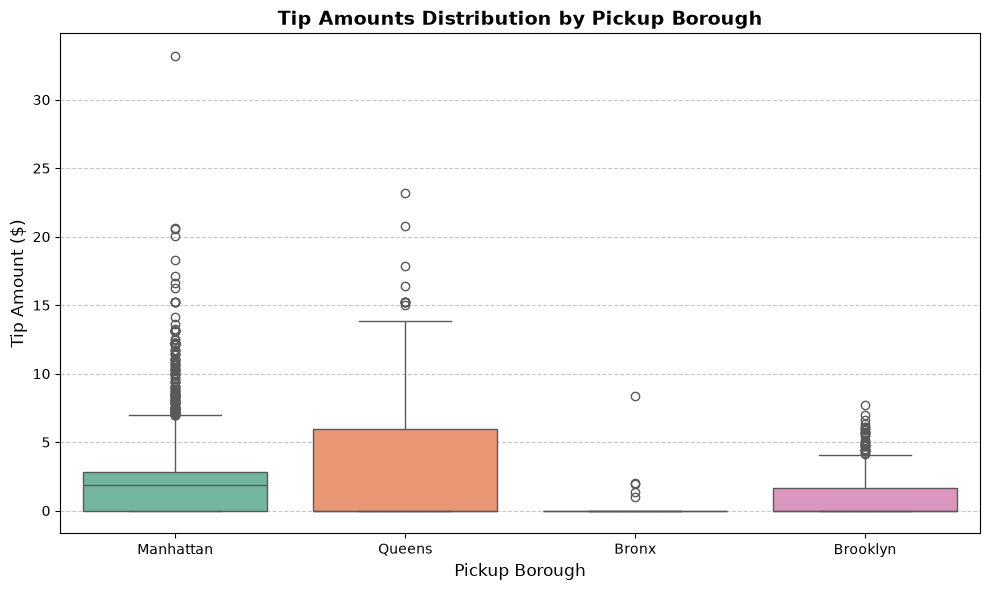

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(x='pickup_borough', y='tip', data=df, palette='Set2')

plt.title('Tip Amounts Distribution by Pickup Borough', fontsize=14, fontweight='bold')
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Tip Amount ($)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

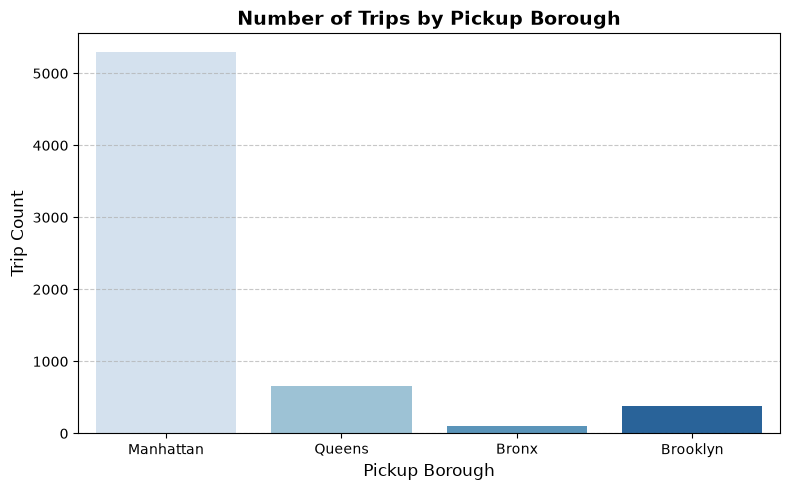

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(
    x='pickup_borough', 
    data=df, 
    hue='pickup_borough', 
    palette='Blues', 
    legend=False
)

plt.title('Number of Trips by Pickup Borough', fontsize=14, fontweight='bold')
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Trip Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

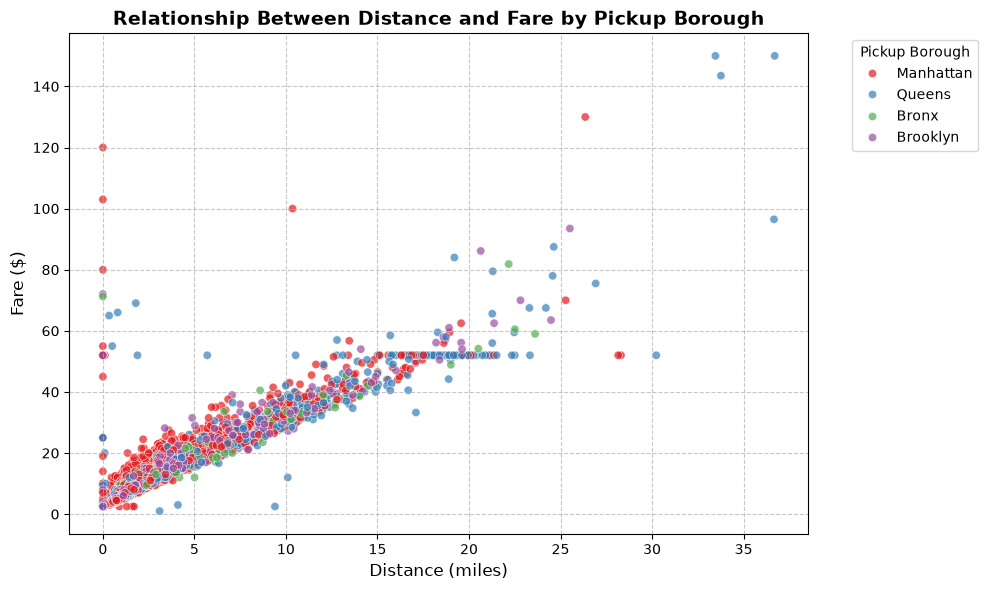

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='distance', 
    y='fare', 
    hue='pickup_borough', 
    data=df, 
    palette='Set1', 
    alpha=0.7
)

plt.title('Relationship Between Distance and Fare by Pickup Borough', fontsize=14, fontweight='bold')
plt.xlabel('Distance (miles)', fontsize=12)
plt.ylabel('Fare ($)', fontsize=12)
plt.legend(title='Pickup Borough', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

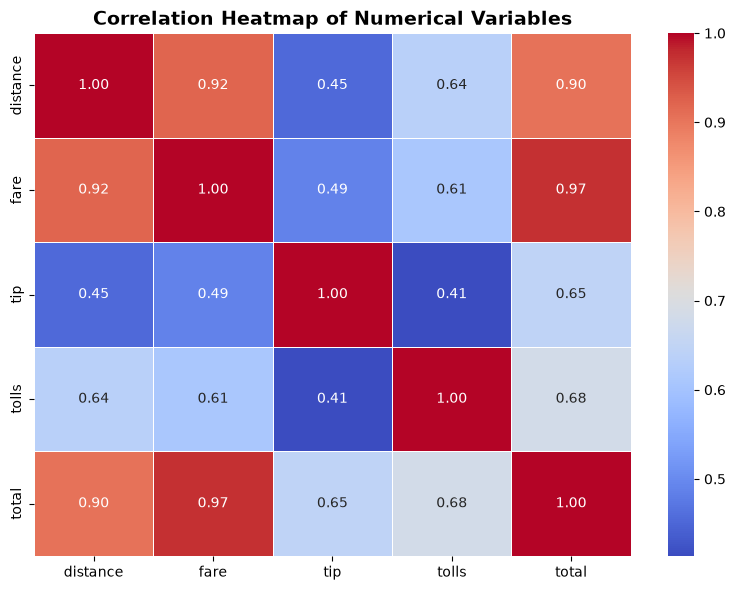

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ['distance', 'fare', 'tip', 'tolls', 'total']
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)

plt.title('Correlation Heatmap of Numerical Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

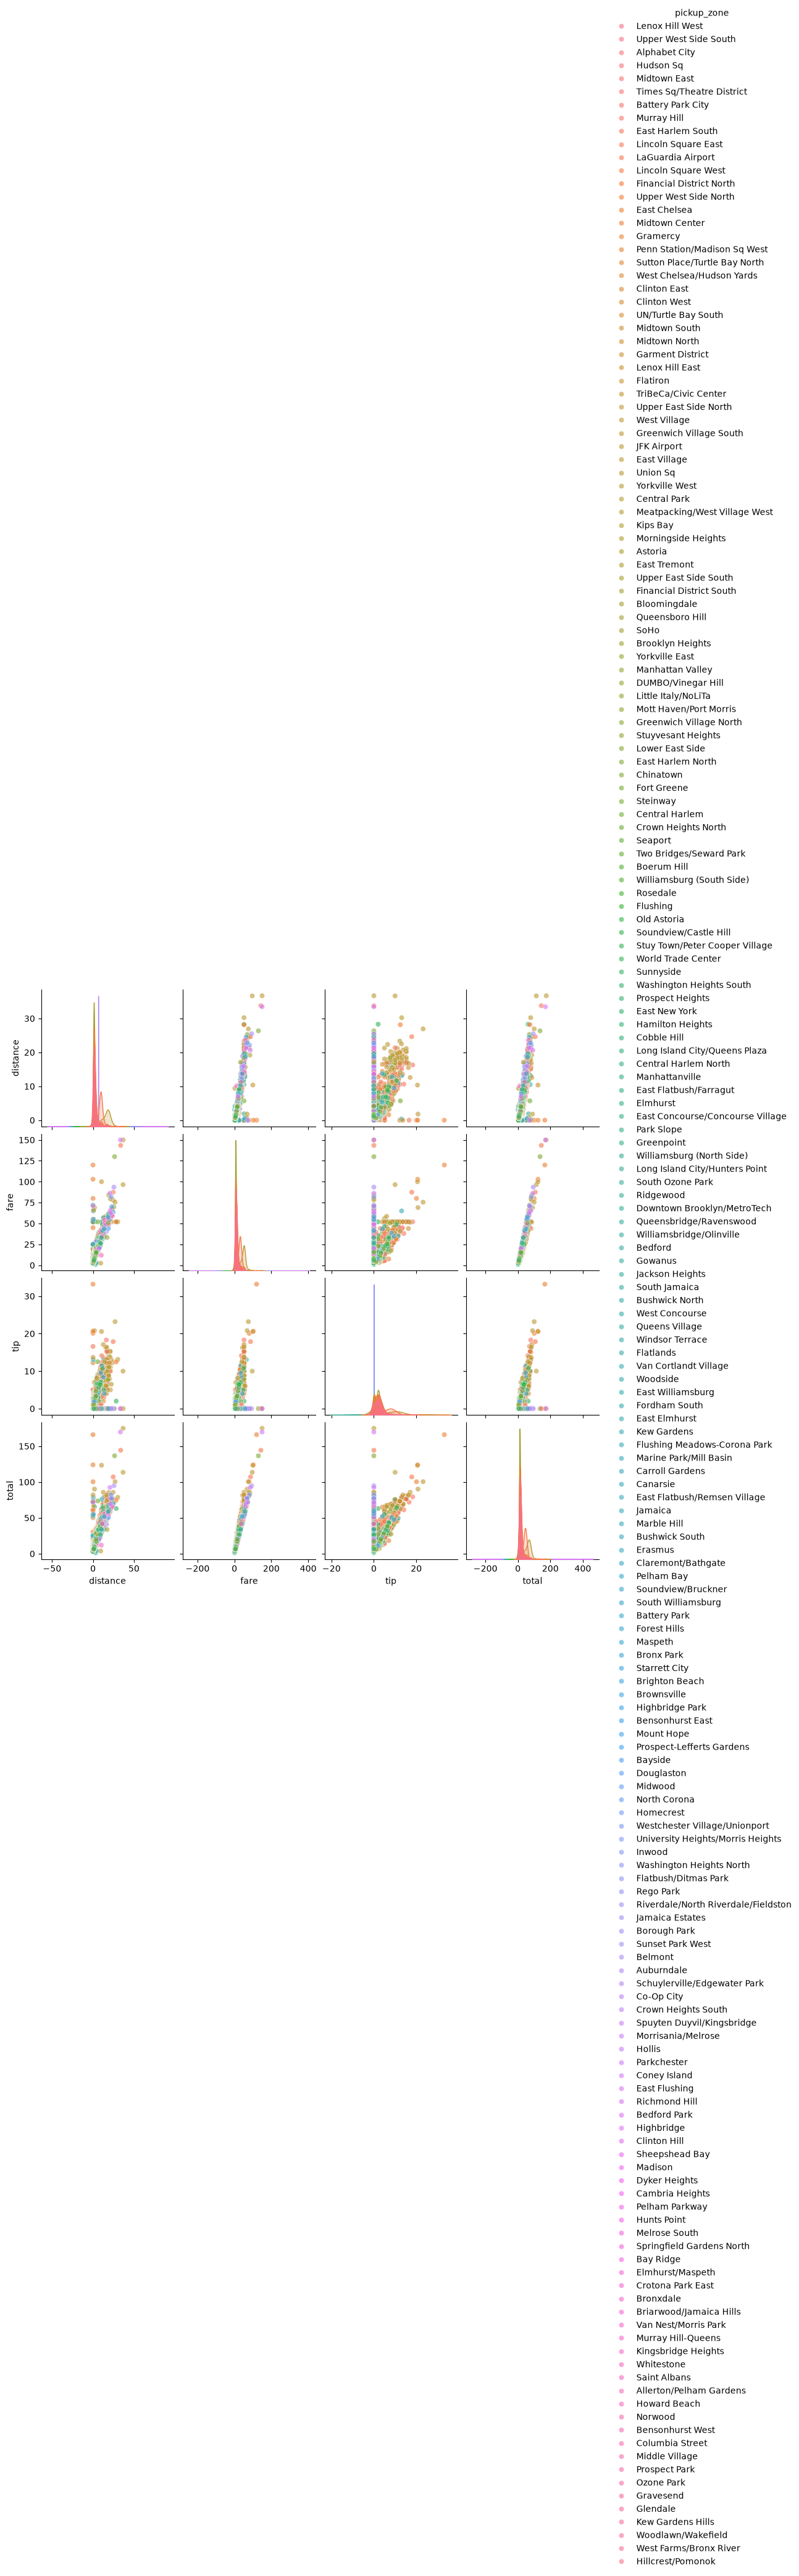

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pair_cols = ['distance', 'fare', 'tip', 'total', 'pickup_zone']

sns.pairplot(df[pair_cols], hue='pickup_zone', palette='husl', plot_kws={'alpha': 0.6})
plt.show()

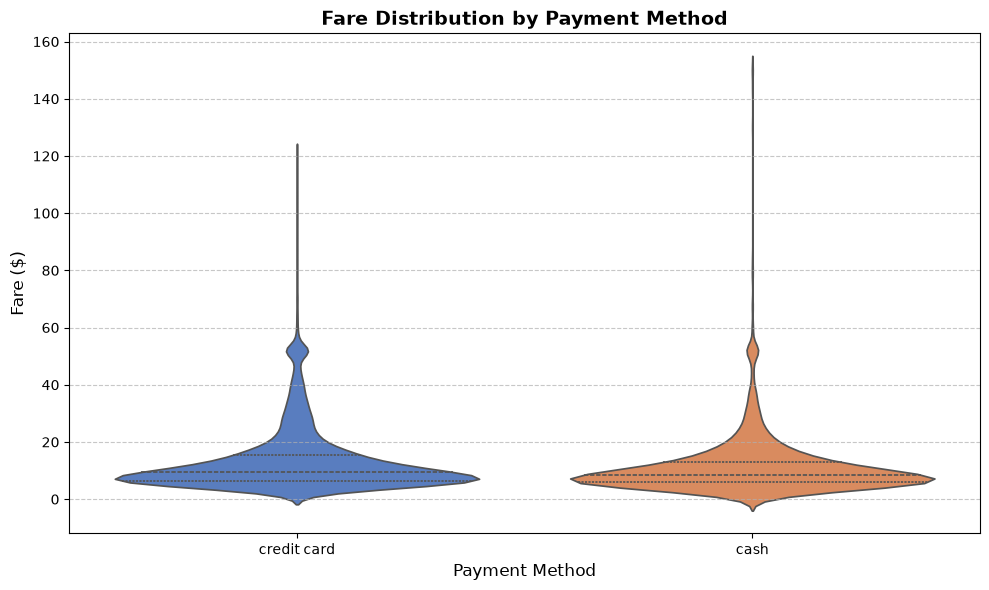

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.violinplot(
    x='payment', 
    y='fare', 
    data=df, 
    hue='payment', 
    palette='muted', 
    legend=False, 
    inner='quartile'
)

plt.title('Fare Distribution by Payment Method', fontsize=14, fontweight='bold')
plt.xlabel('Payment Method', fontsize=12)
plt.ylabel('Fare ($)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()